# SmartServe — Demand Forecasting Model Development

## Business Objective

Develop machine learning models to forecast daily product demand across SmartServe restaurant locations using historical sales, calendar, product, store, weather, and demand-pattern features.

The objective is to improve demand planning, reduce inventory shortages, minimize food waste, and support data-driven operational decisions.

## Project Scope

This notebook covers:

1. Loading preprocessed training and testing datasets.
2. Establishing a baseline forecasting model.
3. Training machine learning models.
4. Evaluating forecasting performance.
5. Comparing candidate models.
6. Identifying important demand drivers.
7. Selecting the best-performing model.

## Prediction Target

**Target Variable:** `sales_qty`

The model predicts the quantity of a product sold at a particular store on a particular date.

## Modeling Approach

A chronological training and testing split is used to preserve the time-dependent nature of demand forecasting and prevent future information from leaking into model training.

- Training dataset: 7,200 observations
- Testing dataset: 1,800 observations
- Training/testing ratio: 80/20
- Input features: 110 numerical features

## Expected Business Outcomes

- More accurate daily demand forecasts.
- Improved inventory replenishment decisions.
- Reduced stockouts and overstocking.
- Lower food waste.
- Better store-level operational planning.

In [1]:
# 1. Environment Setup and Processed Data Loading
# Import libraries and load the preprocessed training and testing datasets.

import sys
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

PROJECT_ROOT = Path.cwd().parent

if str(PROJECT_ROOT) not in sys.path:
    sys.path.append(str(PROJECT_ROOT))

PROCESSED_MODEL_DIR = (
    PROJECT_ROOT / "data" / "processed" / "model"
)

X_train = pd.read_csv(PROCESSED_MODEL_DIR / "X_train.csv")
X_test = pd.read_csv(PROCESSED_MODEL_DIR / "X_test.csv")

y_train = pd.read_csv(PROCESSED_MODEL_DIR / "y_train.csv")["sales_qty"]
y_test = pd.read_csv(PROCESSED_MODEL_DIR / "y_test.csv")["sales_qty"]

sns.set_theme(style="whitegrid")

print("SMARTSERVE DEMAND FORECASTING")
print("=" * 50)

print("Project directory:", PROJECT_ROOT)
print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

print("\nDATA LOADING COMPLETED")

SMARTSERVE DEMAND FORECASTING
Project directory: d:\Data Analysis Projects\SmartServe-Food-Intelligence
Training features: (7200, 110)
Testing features: (1800, 110)
Training target: (7200,)
Testing target: (1800,)

DATA LOADING COMPLETED


TARGET VARIABLE ANALYSIS

Training Target Statistics:


count    7200.000000
mean       32.783056
std        16.986521
min         5.000000
25%        20.000000
50%        29.000000
75%        42.000000
max       115.000000
Name: sales_qty, dtype: float64


Testing Target Statistics:


count    1800.000000
mean       33.680556
std        18.076505
min         6.000000
25%        20.000000
50%        30.000000
75%        43.000000
max       116.000000
Name: sales_qty, dtype: float64


Demand Distribution:
Training observations: 7200
Zero-demand observations: 0
Positive-demand observations: 7200
Minimum demand: 5
Maximum demand: 115
Average demand: 32.78


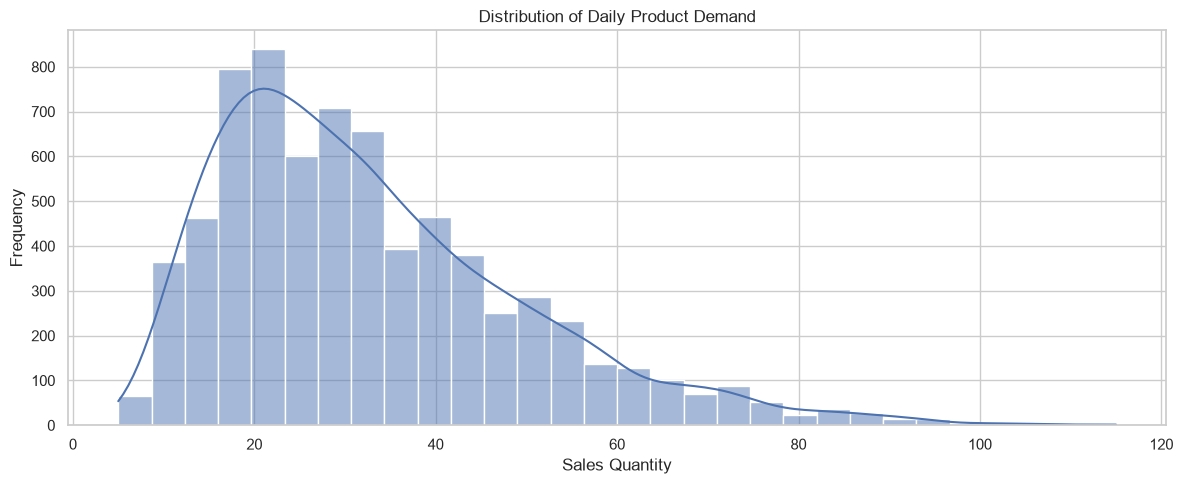


TARGET VARIABLE ANALYSIS COMPLETED


In [2]:
# 2. Target Variable Analysis
# Analyze the distribution and statistical properties of daily demand.

print("TARGET VARIABLE ANALYSIS")
print("=" * 50)

print("\nTraining Target Statistics:")
display(y_train.describe())

print("\nTesting Target Statistics:")
display(y_test.describe())

print("\nDemand Distribution:")
print("Training observations:", len(y_train))
print("Zero-demand observations:", (y_train == 0).sum())
print("Positive-demand observations:", (y_train > 0).sum())
print("Minimum demand:", y_train.min())
print("Maximum demand:", y_train.max())
print("Average demand:", round(y_train.mean(), 2))

plt.figure(figsize=(12, 5))

sns.histplot(
    y_train,
    bins=30,
    kde=True
)

plt.title("Distribution of Daily Product Demand")
plt.xlabel("Sales Quantity")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

print("\nTARGET VARIABLE ANALYSIS COMPLETED")

In [3]:
# 3. Baseline Model Development
# Create a simple mean-based baseline forecasting model.

from sklearn.dummy import DummyRegressor

baseline_model = DummyRegressor(strategy="mean")

baseline_model.fit(
    X_train,
    y_train
)

baseline_predictions = baseline_model.predict(X_test)

print("BASELINE MODEL DEVELOPMENT")
print("=" * 50)

print("Baseline strategy: Mean")
print("Training mean demand:", round(y_train.mean(), 2))
print("Average baseline prediction:", round(baseline_predictions.mean(), 2))
print("Number of test predictions:", len(baseline_predictions))

print("\nBASELINE MODEL DEVELOPMENT COMPLETED")

BASELINE MODEL DEVELOPMENT
Baseline strategy: Mean
Training mean demand: 32.78
Average baseline prediction: 32.78
Number of test predictions: 1800

BASELINE MODEL DEVELOPMENT COMPLETED


In [4]:
# 4. Baseline Model Evaluation
# Evaluate baseline forecasting performance using regression metrics.

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

baseline_mae = mean_absolute_error(
    y_test,
    baseline_predictions
)

baseline_mse = mean_squared_error(
    y_test,
    baseline_predictions
)

baseline_rmse = np.sqrt(baseline_mse)

baseline_r2 = r2_score(
    y_test,
    baseline_predictions
)

baseline_results = pd.DataFrame({
    "Model": ["Mean Baseline"],
    "MAE": [baseline_mae],
    "MSE": [baseline_mse],
    "RMSE": [baseline_rmse],
    "R2": [baseline_r2]
})

print("BASELINE MODEL EVALUATION")
print("=" * 50)

display(baseline_results.round(4))

print("BASELINE MODEL EVALUATION COMPLETED")

BASELINE MODEL EVALUATION


,Model,MAE,MSE,RMSE,R2
0,Mean Baseline,13.924,327.384,18.0938,-0.0025


BASELINE MODEL EVALUATION COMPLETED


In [5]:
# Model Evaluation Utilities
# Reusable regression evaluation functions for SmartServe.

import numpy as np
import pandas as pd

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)


def evaluate_regression_model(
    model_name,
    actual_values,
    predicted_values
):
    """
    Evaluate a regression model using standard metrics.

    Returns:
        dict: Model evaluation metrics.
    """

    mae = mean_absolute_error(
        actual_values,
        predicted_values
    )

    mse = mean_squared_error(
        actual_values,
        predicted_values
    )

    rmse = np.sqrt(mse)

    r2 = r2_score(
        actual_values,
        predicted_values
    )

    results = {
        "Model": model_name,
        "MAE": mae,
        "MSE": mse,
        "RMSE": rmse,
        "R2": r2
    }

    return results


def create_model_comparison(results):
    """
    Convert model evaluation results into a DataFrame.
    """

    comparison = pd.DataFrame(results)

    return comparison.sort_values(
        by="RMSE",
        ascending=True
    ).reset_index(drop=True)

In [6]:
# 6. Import Model Evaluation Functions
# Import and test reusable model evaluation utilities.

from src.model_evaluation import (
    evaluate_regression_model,
    create_model_comparison
)

baseline_evaluation = evaluate_regression_model(
    model_name="Mean Baseline",
    actual_values=y_test,
    predicted_values=baseline_predictions
)

model_results = [baseline_evaluation]

baseline_comparison = create_model_comparison(
    model_results
)

print("MODEL EVALUATION FRAMEWORK")
print("=" * 50)

display(baseline_comparison.round(4))

print("MODEL EVALUATION FUNCTIONS IMPORTED SUCCESSFULLY")

MODEL EVALUATION FRAMEWORK


,Model,MAE,MSE,RMSE,R2
0,Mean Baseline,13.924,327.384,18.0938,-0.0025


MODEL EVALUATION FUNCTIONS IMPORTED SUCCESSFULLY


In [7]:
# 7. Linear Regression Model Development
# Train a Linear Regression model using the prepared features.

from sklearn.linear_model import LinearRegression

linear_model = LinearRegression()

linear_model.fit(
    X_train,
    y_train
)

linear_predictions = linear_model.predict(X_test)

print("LINEAR REGRESSION MODEL DEVELOPMENT")
print("=" * 50)

print("Model:", type(linear_model).__name__)
print("Training observations:", len(X_train))
print("Testing observations:", len(X_test))
print("Number of features:", X_train.shape[1])
print("Predictions generated:", len(linear_predictions))

print("\nLINEAR REGRESSION MODEL TRAINING COMPLETED")

LINEAR REGRESSION MODEL DEVELOPMENT
Model: LinearRegression
Training observations: 7200
Testing observations: 1800
Number of features: 110
Predictions generated: 1800

LINEAR REGRESSION MODEL TRAINING COMPLETED


In [8]:
# 8. Linear Regression Model Evaluation
# Evaluate Linear Regression and compare it with the baseline.

linear_evaluation = evaluate_regression_model(
    model_name="Linear Regression",
    actual_values=y_test,
    predicted_values=linear_predictions
)

model_results.append(linear_evaluation)

model_comparison = create_model_comparison(
    model_results
)

print("LINEAR REGRESSION MODEL EVALUATION")
print("=" * 50)

display(model_comparison.round(4))

print("\nMAE Improvement over Baseline:",
      round(
          (baseline_mae - linear_evaluation["MAE"])
          / baseline_mae * 100,
          2
      ), "%")

print("\nLINEAR REGRESSION EVALUATION COMPLETED")

LINEAR REGRESSION MODEL EVALUATION


,Model,MAE,MSE,RMSE,R2
0,Linear Regression,8.3705,119.2319,10.9193,0.6349
1,Mean Baseline,13.9240,327.3840,18.0938,-0.0025



MAE Improvement over Baseline: 39.88 %

LINEAR REGRESSION EVALUATION COMPLETED


In [9]:
# 9. Random Forest Model Development
# Train a Random Forest regression model.

from sklearn.ensemble import RandomForestRegressor

random_forest_model = RandomForestRegressor(
    n_estimators=200,
    max_depth=15,
    min_samples_split=5,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)

random_forest_model.fit(
    X_train,
    y_train
)

rf_predictions = random_forest_model.predict(X_test)

print("RANDOM FOREST MODEL DEVELOPMENT")
print("=" * 50)

print("Model:", type(random_forest_model).__name__)
print("Number of trees:", 200)
print("Maximum depth:", 15)
print("Training observations:", len(X_train))
print("Testing observations:", len(X_test))
print("Predictions generated:", len(rf_predictions))

print("\nRANDOM FOREST MODEL TRAINING COMPLETED")

RANDOM FOREST MODEL DEVELOPMENT
Model: RandomForestRegressor
Number of trees: 200
Maximum depth: 15
Training observations: 7200
Testing observations: 1800
Predictions generated: 1800

RANDOM FOREST MODEL TRAINING COMPLETED


In [10]:
# 10. Random Forest Model Evaluation
# Evaluate Random Forest and compare all trained models.

rf_evaluation = evaluate_regression_model(
    model_name="Random Forest",
    actual_values=y_test,
    predicted_values=rf_predictions
)

model_results.append(rf_evaluation)

model_comparison = create_model_comparison(
    model_results
)

print("RANDOM FOREST MODEL EVALUATION")
print("=" * 50)

display(model_comparison.round(4))

print("\nMAE Improvement over Baseline:",
      round(
          (baseline_mae - rf_evaluation["MAE"])
          / baseline_mae * 100,
          2
      ), "%")

print("\nRANDOM FOREST EVALUATION COMPLETED")

RANDOM FOREST MODEL EVALUATION


,Model,MAE,MSE,RMSE,R2
0,Linear Regression,8.3705,119.2319,10.9193,0.6349
1,Random Forest,8.5053,122.9657,11.0890,0.6235
2,Mean Baseline,13.9240,327.3840,18.0938,-0.0025



MAE Improvement over Baseline: 38.92 %

RANDOM FOREST EVALUATION COMPLETED


In [11]:
# 11. Gradient Boosting Model Development
# Train a Gradient Boosting regression model.

from sklearn.ensemble import GradientBoostingRegressor

gradient_boosting_model = GradientBoostingRegressor(
    n_estimators=200,
    learning_rate=0.05,
    max_depth=3,
    min_samples_split=5,
    min_samples_leaf=2,
    loss="squared_error",
    random_state=42
)

gradient_boosting_model.fit(
    X_train,
    y_train
)

gb_predictions = gradient_boosting_model.predict(X_test)

print("GRADIENT BOOSTING MODEL DEVELOPMENT")
print("=" * 50)

print("Model:", type(gradient_boosting_model).__name__)
print("Number of estimators:", 200)
print("Learning rate:", 0.05)
print("Maximum depth:", 3)
print("Training observations:", len(X_train))
print("Testing observations:", len(X_test))
print("Predictions generated:", len(gb_predictions))

print("\nGRADIENT BOOSTING MODEL TRAINING COMPLETED")

GRADIENT BOOSTING MODEL DEVELOPMENT
Model: GradientBoostingRegressor
Number of estimators: 200
Learning rate: 0.05
Maximum depth: 3
Training observations: 7200
Testing observations: 1800
Predictions generated: 1800

GRADIENT BOOSTING MODEL TRAINING COMPLETED


In [12]:
# 12. Gradient Boosting Model Evaluation
# Evaluate Gradient Boosting and compare all trained models.

gb_evaluation = evaluate_regression_model(
    model_name="Gradient Boosting",
    actual_values=y_test,
    predicted_values=gb_predictions
)

model_results.append(gb_evaluation)

model_comparison = create_model_comparison(
    model_results
)

print("GRADIENT BOOSTING MODEL EVALUATION")
print("=" * 50)

display(model_comparison.round(4))

print("\nMAE Improvement over Baseline:",
      round(
          (baseline_mae - gb_evaluation["MAE"])
          / baseline_mae * 100,
          2
      ), "%")

print("\nGRADIENT BOOSTING EVALUATION COMPLETED")

GRADIENT BOOSTING MODEL EVALUATION


,Model,MAE,MSE,RMSE,R2
0,Gradient Boosting,8.2923,117.8637,10.8565,0.6391
1,Linear Regression,8.3705,119.2319,10.9193,0.6349
2,Random Forest,8.5053,122.9657,11.0890,0.6235
3,Mean Baseline,13.9240,327.3840,18.0938,-0.0025



MAE Improvement over Baseline: 40.45 %

GRADIENT BOOSTING EVALUATION COMPLETED


In [13]:
# 13. XGBoost Availability Check
# Check whether XGBoost is installed.

try:
    import xgboost as xgb

    print("XGBOOST AVAILABLE")
    print("=" * 50)
    print("XGBoost version:", xgb.__version__)

except ImportError:
    print("XGBOOST NOT INSTALLED")
    print("XGBoost will be skipped unless installed.")

XGBOOST AVAILABLE
XGBoost version: 3.4.1


In [14]:
# 14. XGBoost Model Development
# Train an XGBoost regression model.

from xgboost import XGBRegressor

xgboost_model = XGBRegressor(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=5,
    min_child_weight=3,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="reg:squarederror",
    eval_metric="rmse",
    random_state=42,
    n_jobs=-1
)

xgboost_model.fit(
    X_train,
    y_train
)

xgb_predictions = xgboost_model.predict(X_test)

print("XGBOOST MODEL DEVELOPMENT")
print("=" * 50)

print("Model:", type(xgboost_model).__name__)
print("Number of estimators:", 300)
print("Learning rate:", 0.05)
print("Maximum depth:", 5)
print("Training observations:", len(X_train))
print("Testing observations:", len(X_test))
print("Predictions generated:", len(xgb_predictions))

print("\nXGBOOST MODEL TRAINING COMPLETED")

XGBOOST MODEL DEVELOPMENT
Model: XGBRegressor
Number of estimators: 300
Learning rate: 0.05
Maximum depth: 5
Training observations: 7200
Testing observations: 1800
Predictions generated: 1800

XGBOOST MODEL TRAINING COMPLETED


In [15]:
# 15. XGBoost Model Evaluation
# Evaluate XGBoost and compare all trained models.

xgb_evaluation = evaluate_regression_model(
    model_name="XGBoost",
    actual_values=y_test,
    predicted_values=xgb_predictions
)

model_results.append(xgb_evaluation)

model_comparison = create_model_comparison(
    model_results
)

print("XGBOOST MODEL EVALUATION")
print("=" * 50)

display(model_comparison.round(4))

print("\nMAE Improvement over Baseline:",
      round(
          (baseline_mae - xgb_evaluation["MAE"])
          / baseline_mae * 100,
          2
      ), "%")

print("\nXGBOOST EVALUATION COMPLETED")

XGBOOST MODEL EVALUATION


,Model,MAE,MSE,RMSE,R2
0,Gradient Boosting,8.2923,117.8637,10.8565,0.6391
1,Linear Regression,8.3705,119.2319,10.9193,0.6349
2,XGBoost,8.3980,122.1208,11.0508,0.6261
3,Random Forest,8.5053,122.9657,11.0890,0.6235
4,Mean Baseline,13.9240,327.3840,18.0938,-0.0025



MAE Improvement over Baseline: 39.69 %

XGBOOST EVALUATION COMPLETED


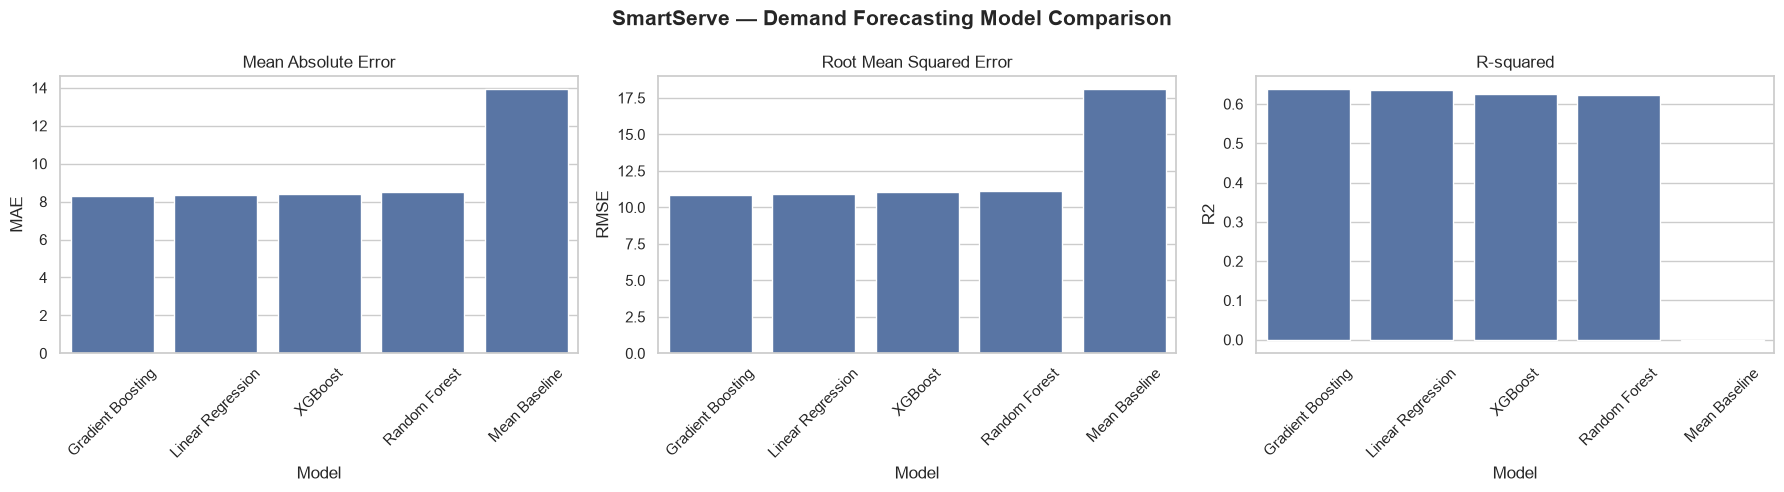

MODEL PERFORMANCE VISUALIZATION COMPLETED


In [16]:
# 16. Model Performance Visualization
# Compare model performance using MAE, RMSE, and R2.

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

metrics = ["MAE", "RMSE", "R2"]
titles = [
    "Mean Absolute Error",
    "Root Mean Squared Error",
    "R-squared"
]

for ax, metric, title in zip(axes, metrics, titles):

    sns.barplot(
        data=model_comparison,
        x="Model",
        y=metric,
        ax=ax
    )

    ax.set_title(title, fontsize=12)
    ax.set_xlabel("Model")
    ax.set_ylabel(metric)
    ax.tick_params(axis="x", rotation=45)

plt.suptitle(
    "SmartServe — Demand Forecasting Model Comparison",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

print("MODEL PERFORMANCE VISUALIZATION COMPLETED")

In [17]:
# 17. Actual vs Predicted Demand Analysis
# Compare actual demand with Gradient Boosting predictions.

actual_vs_predicted = pd.DataFrame({
    "Actual Demand": y_test.values,
    "Predicted Demand": gb_predictions
})

actual_vs_predicted["Prediction Error"] = (
    actual_vs_predicted["Actual Demand"]
    - actual_vs_predicted["Predicted Demand"]
)

print("ACTUAL VS PREDICTED DEMAND")
print("=" * 50)

display(actual_vs_predicted.head(10).round(2))

print("\nActual demand average:",
      round(actual_vs_predicted["Actual Demand"].mean(), 2))

print("Predicted demand average:",
      round(actual_vs_predicted["Predicted Demand"].mean(), 2))

print("Mean prediction error:",
      round(actual_vs_predicted["Prediction Error"].mean(), 2))

print("\nACTUAL VS PREDICTED ANALYSIS COMPLETED")

ACTUAL VS PREDICTED DEMAND


,Actual Demand,Predicted Demand,Prediction Error
0,69,52.09,16.91
1,48,58.34,-10.34
2,39,64.09,-25.09
3,44,58.98,-14.98
4,37,58.57,-21.57
5,79,53.02,25.98
6,52,61.39,-9.39
7,33,54.67,-21.67
8,51,72.40,-21.40
9,55,65.41,-10.41



Actual demand average: 33.68
Predicted demand average: 33.83
Mean prediction error: -0.15

ACTUAL VS PREDICTED ANALYSIS COMPLETED


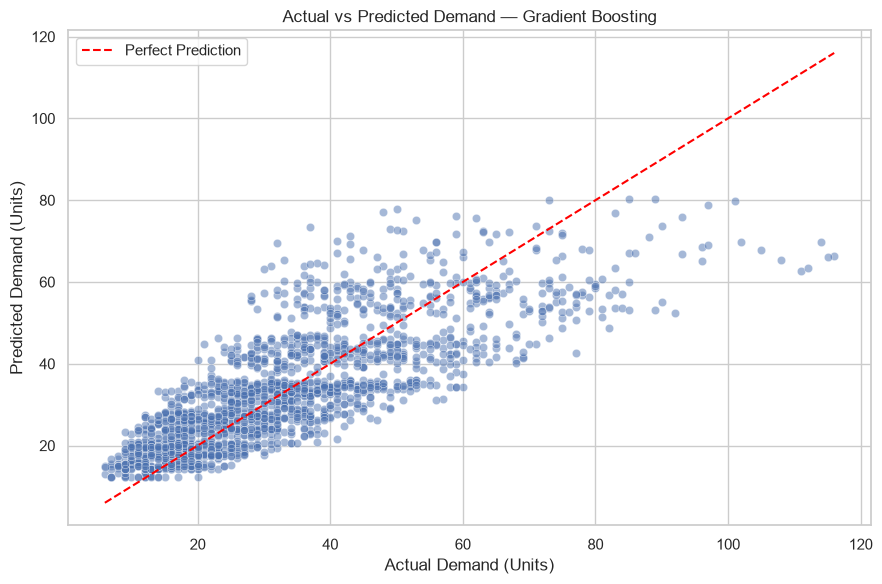

ACTUAL VS PREDICTED VISUALIZATION COMPLETED


In [18]:
# 18. Actual vs Predicted Demand Visualization
# Visualize prediction accuracy using a scatter plot.

plt.figure(figsize=(9, 6))

sns.scatterplot(
    x=actual_vs_predicted["Actual Demand"],
    y=actual_vs_predicted["Predicted Demand"],
    alpha=0.5
)

min_value = min(
    actual_vs_predicted["Actual Demand"].min(),
    actual_vs_predicted["Predicted Demand"].min()
)

max_value = max(
    actual_vs_predicted["Actual Demand"].max(),
    actual_vs_predicted["Predicted Demand"].max()
)

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--",
    color="red",
    label="Perfect Prediction"
)

plt.title("Actual vs Predicted Demand — Gradient Boosting")
plt.xlabel("Actual Demand (Units)")
plt.ylabel("Predicted Demand (Units)")
plt.legend()
plt.tight_layout()
plt.show()

print("ACTUAL VS PREDICTED VISUALIZATION COMPLETED")

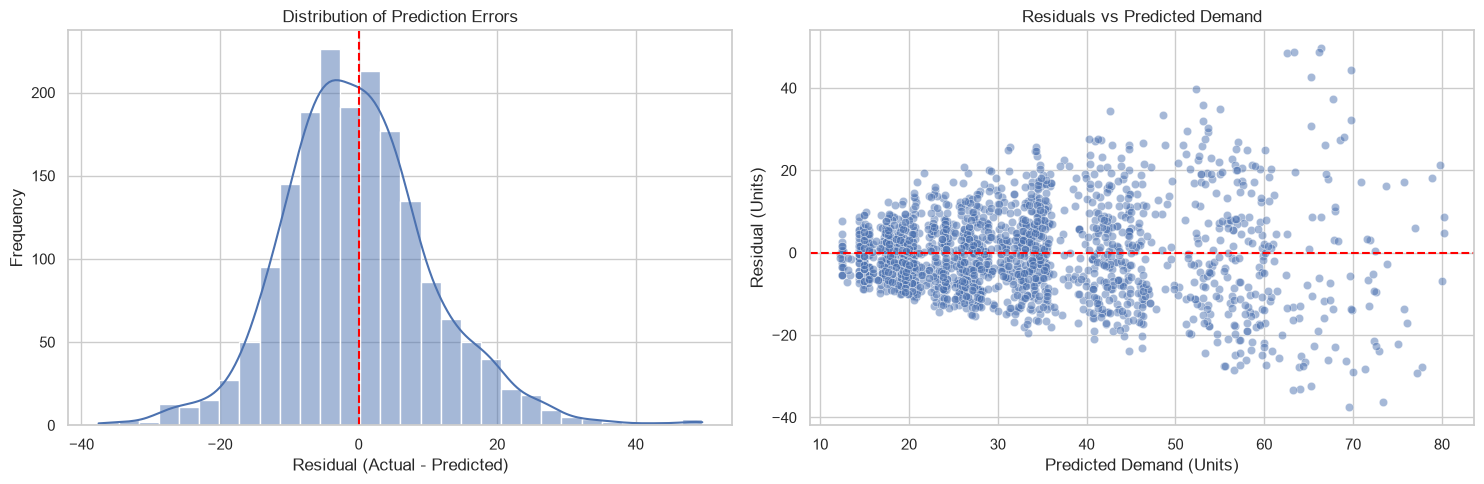

RESIDUAL ANALYSIS
Mean residual: -0.1501
Residual standard deviation: 10.8585
Maximum residual: 49.6
Minimum residual: -37.53

RESIDUAL ANALYSIS COMPLETED


In [19]:
# 19. Residual Analysis
# Examine the distribution and patterns of prediction errors.

residuals = actual_vs_predicted["Prediction Error"]

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.histplot(
    residuals,
    bins=30,
    kde=True,
    ax=axes[0]
)

axes[0].axvline(
    0,
    color="red",
    linestyle="--"
)

axes[0].set_title("Distribution of Prediction Errors")
axes[0].set_xlabel("Residual (Actual - Predicted)")
axes[0].set_ylabel("Frequency")

sns.scatterplot(
    x=actual_vs_predicted["Predicted Demand"],
    y=residuals,
    alpha=0.5,
    ax=axes[1]
)

axes[1].axhline(
    0,
    color="red",
    linestyle="--"
)

axes[1].set_title("Residuals vs Predicted Demand")
axes[1].set_xlabel("Predicted Demand (Units)")
axes[1].set_ylabel("Residual (Units)")

plt.tight_layout()
plt.show()

print("RESIDUAL ANALYSIS")
print("=" * 50)

print("Mean residual:", round(residuals.mean(), 4))
print("Residual standard deviation:", round(residuals.std(), 4))
print("Maximum residual:", round(residuals.max(), 2))
print("Minimum residual:", round(residuals.min(), 2))

print("\nRESIDUAL ANALYSIS COMPLETED")

In [20]:
# 20. Demand-Level Prediction Error Analysis
# Evaluate model errors across actual demand ranges.

error_analysis = actual_vs_predicted.copy()

error_analysis["Absolute Error"] = (
    error_analysis["Prediction Error"].abs()
)

error_analysis["Demand Level"] = pd.cut(
    error_analysis["Actual Demand"],
    bins=[0, 20, 40, 60, 80, 120],
    labels=[
        "Low (1-20)",
        "Moderate (21-40)",
        "Medium (41-60)",
        "High (61-80)",
        "Very High (81-120)"
    ]
)

demand_error_summary = (
    error_analysis
    .groupby("Demand Level", observed=False)
    .agg(
        Observations=("Actual Demand", "count"),
        Average_Actual_Demand=("Actual Demand", "mean"),
        Average_Predicted_Demand=("Predicted Demand", "mean"),
        MAE=("Absolute Error", "mean"),
        Mean_Residual=("Prediction Error", "mean")
    )
    .reset_index()
)

print("PREDICTION ERROR BY DEMAND LEVEL")
print("=" * 65)

display(demand_error_summary.round(2))

print("\nDEMAND-LEVEL ERROR ANALYSIS COMPLETED")

PREDICTION ERROR BY DEMAND LEVEL


,Demand Level,Observations,Average_Actual_Demand,Average_Predicted_Demand,MAE,Mean_Residual
0,Low (1-20),483,15.12,20.48,6.00,-5.36
1,Moderate (21-40),800,30.05,32.06,6.95,-2.01
2,Medium (41-60),357,48.71,45.21,10.30,3.51
3,High (61-80),123,68.78,55.55,14.21,13.23
4,Very High (81-120),37,92.62,64.37,28.25,28.25



DEMAND-LEVEL ERROR ANALYSIS COMPLETED


GRADIENT BOOSTING FEATURE IMPORTANCE


,Feature,Importance
0,sales_rolling_mean_28,0.82640
1,sales_rolling_mean_14,0.05308
2,calendar_day_of_week,0.02476
3,calendar_is_weekend,0.02202
4,sales_rolling_mean_7,0.01143
5,store_store_type_Flagship,0.00923
6,product_shelf_life_hours,0.00892
7,weather_temperature,0.00613
8,sales_lag_28,0.00387
9,product_subcategory_Coffee,0.00369


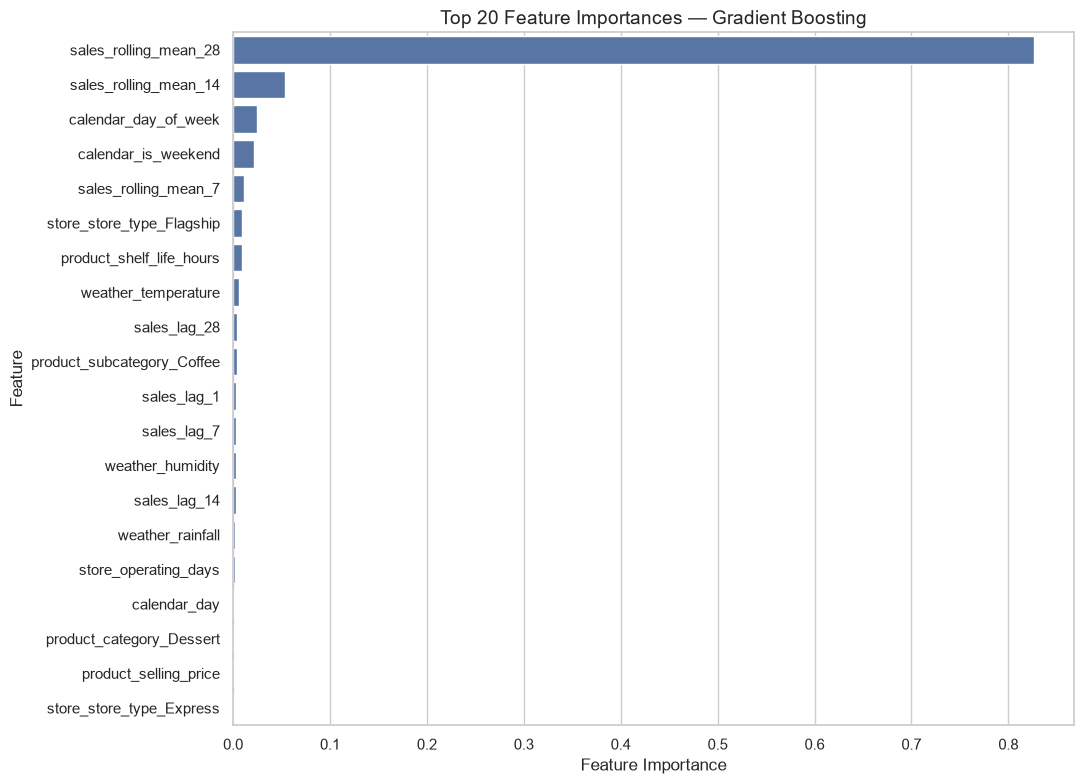


FEATURE IMPORTANCE ANALYSIS COMPLETED


In [21]:
# 21. Gradient Boosting Feature Importance
# Identify the most influential demand forecasting features.

feature_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": gradient_boosting_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
).reset_index(drop=True)

print("GRADIENT BOOSTING FEATURE IMPORTANCE")
print("=" * 60)

display(feature_importance.head(20).round(5))

plt.figure(figsize=(11, 8))

sns.barplot(
    data=feature_importance.head(20),
    x="Importance",
    y="Feature"
)

plt.title(
    "Top 20 Feature Importances — Gradient Boosting",
    fontsize=14
)

plt.xlabel("Feature Importance")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()

print("\nFEATURE IMPORTANCE ANALYSIS COMPLETED")

In [22]:
# 22. Permutation Feature Importance
# Evaluate feature importance using the testing dataset.

from sklearn.inspection import permutation_importance

permutation_results = permutation_importance(
    gradient_boosting_model,
    X_test,
    y_test,
    scoring="neg_mean_absolute_error",
    n_repeats=10,
    random_state=42,
    n_jobs=-1
)

permutation_importance_df = pd.DataFrame({
    "Feature": X_test.columns,
    "Importance_Mean": permutation_results.importances_mean,
    "Importance_Std": permutation_results.importances_std
})

permutation_importance_df = (
    permutation_importance_df
    .sort_values(
        by="Importance_Mean",
        ascending=False
    )
    .reset_index(drop=True)
)

print("PERMUTATION FEATURE IMPORTANCE")
print("=" * 60)

display(permutation_importance_df.head(20).round(5))

print("\nPERMUTATION IMPORTANCE ANALYSIS COMPLETED")

PERMUTATION FEATURE IMPORTANCE


,Feature,Importance_Mean,Importance_Std
0,sales_rolling_mean_28,3.95584,0.14714
1,product_shelf_life_hours,0.48840,0.07119
2,store_store_type_Flagship,0.38331,0.07163
3,sales_rolling_mean_14,0.31287,0.05127
4,calendar_day_of_week,0.20650,0.02728
5,calendar_is_weekend,0.14251,0.03061
6,product_subcategory_Coffee,0.13905,0.03692
7,sales_lag_1,0.03648,0.01513
8,sales_lag_7,0.03601,0.01163
9,sales_rolling_mean_7,0.03515,0.01528



PERMUTATION IMPORTANCE ANALYSIS COMPLETED


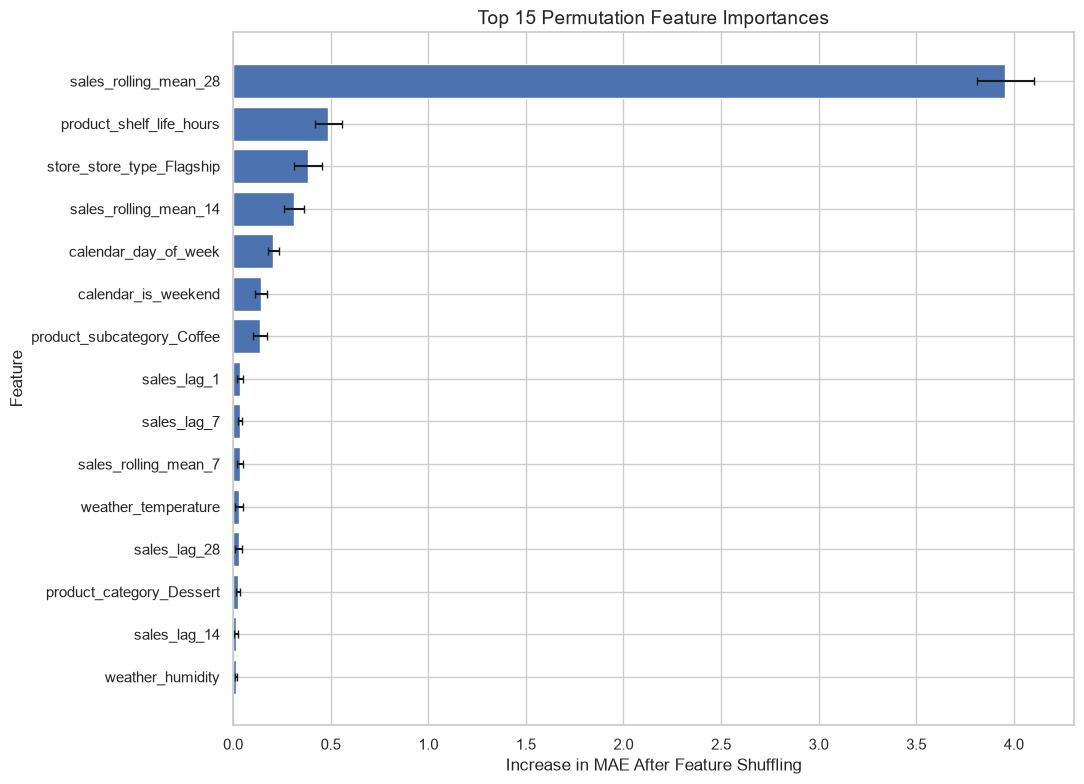

PERMUTATION IMPORTANCE VISUALIZATION COMPLETED


In [23]:
# 23. Permutation Feature Importance Visualization
# Visualize the top 15 features by permutation importance.

top_permutation_features = (
    permutation_importance_df
    .head(15)
    .sort_values(
        by="Importance_Mean",
        ascending=True
    )
)

plt.figure(figsize=(11, 8))

plt.barh(
    top_permutation_features["Feature"],
    top_permutation_features["Importance_Mean"],
    xerr=top_permutation_features["Importance_Std"],
    capsize=3
)

plt.title(
    "Top 15 Permutation Feature Importances",
    fontsize=14
)

plt.xlabel("Increase in MAE After Feature Shuffling")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()

print("PERMUTATION IMPORTANCE VISUALIZATION COMPLETED")

In [24]:
# 24. Model Performance Summary
# Consolidate evaluation results for all trained models.

final_model_comparison = create_model_comparison(
    model_results
)

print("SMARTSERVE — MODEL PERFORMANCE SUMMARY")
print("=" * 65)

display(
    final_model_comparison.round(4)
)

best_model_name = final_model_comparison.iloc[0]["Model"]

print("\nBEST PERFORMING MODEL:", best_model_name)

print(
    "Best MAE:",
    round(final_model_comparison.iloc[0]["MAE"], 4)
)

print(
    "Best RMSE:",
    round(final_model_comparison.iloc[0]["RMSE"], 4)
)

print(
    "Best R2:",
    round(final_model_comparison.iloc[0]["R2"], 4)
)

print("\nMODEL PERFORMANCE SUMMARY COMPLETED")

SMARTSERVE — MODEL PERFORMANCE SUMMARY


,Model,MAE,MSE,RMSE,R2
0,Gradient Boosting,8.2923,117.8637,10.8565,0.6391
1,Linear Regression,8.3705,119.2319,10.9193,0.6349
2,XGBoost,8.3980,122.1208,11.0508,0.6261
3,Random Forest,8.5053,122.9657,11.0890,0.6235
4,Mean Baseline,13.9240,327.3840,18.0938,-0.0025



BEST PERFORMING MODEL: Gradient Boosting
Best MAE: 8.2923
Best RMSE: 10.8565
Best R2: 0.6391

MODEL PERFORMANCE SUMMARY COMPLETED


In [25]:
# 25. Save the Best Performing Model
# Save the Gradient Boosting model for future predictions.

import joblib

MODEL_DIR = PROJECT_ROOT / "models"
MODEL_DIR.mkdir(parents=True, exist_ok=True)

BEST_MODEL_PATH = MODEL_DIR / "gradient_boosting_model.pkl"

joblib.dump(
    gradient_boosting_model,
    BEST_MODEL_PATH
)

print("BEST MODEL SAVED SUCCESSFULLY")
print("=" * 50)

print("Selected model:", best_model_name)
print("Model path:", BEST_MODEL_PATH)
print("Model file exists:", BEST_MODEL_PATH.exists())

print("\nMODEL SAVING COMPLETED")

BEST MODEL SAVED SUCCESSFULLY
Selected model: Gradient Boosting
Model path: d:\Data Analysis Projects\SmartServe-Food-Intelligence\models\gradient_boosting_model.pkl
Model file exists: True

MODEL SAVING COMPLETED


In [26]:
# 26. Saved Model Verification
# Load the saved model and verify prediction consistency.

import joblib
import numpy as np

loaded_model = joblib.load(BEST_MODEL_PATH)

loaded_predictions = loaded_model.predict(X_test)

predictions_match = np.allclose(
    gb_predictions,
    loaded_predictions
)

print("SAVED MODEL VERIFICATION")
print("=" * 50)

print("Loaded model:", type(loaded_model).__name__)
print("Original predictions:", len(gb_predictions))
print("Loaded model predictions:", len(loaded_predictions))
print("Predictions match:", predictions_match)

print(
    "Maximum prediction difference:",
    np.max(np.abs(gb_predictions - loaded_predictions))
)

print("\nSAVED MODEL VERIFICATION COMPLETED")

SAVED MODEL VERIFICATION
Loaded model: GradientBoostingRegressor
Original predictions: 1800
Loaded model predictions: 1800
Predictions match: True
Maximum prediction difference: 0.0

SAVED MODEL VERIFICATION COMPLETED


In [27]:
# 27. Final Model Evaluation
# Evaluate the selected Gradient Boosting model.

from src.model_evaluation import evaluate_regression_model

final_model_metrics = evaluate_regression_model(
    "Gradient Boosting",
    y_test,
    loaded_predictions
)

print("FINAL DEMAND FORECASTING MODEL EVALUATION")
print("=" * 55)

for metric, value in final_model_metrics.items():
    if isinstance(value, (int, float)):
        print(f"{metric}: {value:.4f}")
    else:
        print(f"{metric}: {value}")

print("\nFINAL MODEL EVALUATION COMPLETED")

FINAL DEMAND FORECASTING MODEL EVALUATION
Model: Gradient Boosting
MAE: 8.2923
MSE: 117.8637
RMSE: 10.8565
R2: 0.6391

FINAL MODEL EVALUATION COMPLETED


In [28]:
# 28. Save Final Model Evaluation Report

import pandas as pd

evaluation_report = pd.DataFrame(
    [final_model_metrics]
)

REPORT_DIR = PROJECT_ROOT / "reports" / "model_evaluation"
REPORT_DIR.mkdir(parents=True, exist_ok=True)

REPORT_PATH = REPORT_DIR / "final_model_evaluation.csv"

evaluation_report.to_csv(
    REPORT_PATH,
    index=False
)

print("FINAL MODEL EVALUATION REPORT SAVED")
print("=" * 55)

print("Report path:", REPORT_PATH)
print("File exists:", REPORT_PATH.exists())

display(evaluation_report.round(4))

print("\nREPORT SAVING COMPLETED")

FINAL MODEL EVALUATION REPORT SAVED
Report path: d:\Data Analysis Projects\SmartServe-Food-Intelligence\reports\model_evaluation\final_model_evaluation.csv
File exists: True


,Model,MAE,MSE,RMSE,R2
0,Gradient Boosting,8.2923,117.8637,10.8565,0.6391



REPORT SAVING COMPLETED


## 29. Demand Forecasting Model Development Summary

### Business Objective
Develop machine learning models to forecast daily product demand across restaurant locations using historical sales, product, store, calendar, weather, and operational features.

### Models Developed
- Mean Baseline
- Linear Regression
- Random Forest
- Gradient Boosting
- XGBoost

### Best Performing Model
Gradient Boosting was the strongest candidate based on the evaluated test-set metrics.

### Final Model Performance

| Metric | Result |
|---|---:|
| MAE | 8.2923 |
| MSE | 117.8637 |
| RMSE | 10.8565 |
| R² | 0.6391 |

### Key Findings
- Gradient Boosting achieved a 40.45% MAE improvement over the mean baseline.
- Historical demand patterns, particularly the 28-day rolling average, were the most influential predictive features.
- The model performed better on low and moderate demand observations than on very high demand observations.
- High-demand predictions tended to be underestimated, indicating an opportunity for further model improvement.

### Model Artifacts
- Trained model: `models/gradient_boosting_model.pkl`
- Evaluation report: `reports/model_evaluation/final_model_evaluation.csv`

### Important Evaluation Note
The reported metrics represent rolling one-step-ahead predictions on the chronological test period. The test set was also used during model comparison and feature-importance analysis, so these results should be treated as exploratory holdout performance rather than an entirely untouched final benchmark.

### Conclusion
The Gradient Boosting model provides a useful foundation for restaurant demand forecasting. Its predictions can support inventory planning, preparation decisions, stockout reduction, and food-waste management. Further time-based validation and model refinement are recommended before operational deployment.